# 05 — Collateral

**Spec R8–R9:** how much do netting and a simple collateral agreement (CSA) reduce exposure and CVA?

1. Add a simplified one-way CSA: threshold, minimum transfer amount (MTA) and margin period of risk (MPoR).
2. Measure collateralized EE and CVA on exactly the Phase D paths.
3. Compare gross → netted → netted + CSA, and test sensitivity to the margin period of risk.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
%matplotlib inline

from src.collateral import collateral_analysis
from src.config import (BASE_SIMULATION, BRIDGE_SEED_OFFSET, COUNTERPARTIES_FILE, CSA_SCENARIOS, CURVE_FILE,
                        HW_PARAMS, MPOR_GRID_DAYS, PFE_QUANTILE, PORTFOLIO_FILE)
from src.credit import load_counterparties
from src.curves import load_treasury_curve
from src.cva import estimate_cva
from src.exposure import netted_exposure
from src.instruments import load_portfolio
from src.plotting import plot_collateral_profiles, plot_cva_mitigation
from src.simulation import build_time_grid, revalue_portfolio, simulate_paths

pd.set_option('display.float_format', '{:,.2f}'.format)
curve = load_treasury_curve(CURVE_FILE)
portfolio = load_portfolio(PORTFOLIO_FILE)
credits = load_counterparties(COUNTERPARTIES_FILE)
grid = build_time_grid(portfolio, step=BASE_SIMULATION.time_step)
paths = simulate_paths(HW_PARAMS, grid, BASE_SIMULATION.n_paths, np.random.default_rng(BASE_SIMULATION.seed))

## 1. The collateral model

Only the counterparty posts collateral, consistent with unilateral CVA. If it defaults at $t$, the last collateral call it met was at $t-\text{MPoR}$:

$$C(t) = \max\big(V(t-\text{MPoR}) - H - \text{MTA},\,0\big), \qquad E_c(t) = \max\big(V(t) - C(t),\,0\big)$$

$V$ is the netted value to us, $H$ the threshold and MTA the minimum transfer amount. Collateral can only reduce exposure ($C \ge 0$). A tighter threshold reduces it on every path, and $H = \infty$ gives back the uncollateralized exposure.

**Simplifications, stated:**
- MTA is added to the threshold instead of applying a path-dependent call rule.
- Both parties keep paying coupons during the MPoR.
- There is no initial margin, independent amount, haircut or dispute.
- The MPoR is two weeks in the base scenarios.

## 2. Look-back dates on the same paths

$V(t - \text{MPoR})$ is needed between grid dates. Re-simulating on a finer grid would change the random draws, so the uncollateralized CVA would no longer equal the Phase D headline. Instead, each look-back date is filled in with an **exact Gaussian bridge**: $(x, \int x)$ is drawn from its conditional distribution given the neighbouring grid dates. Because the model is Markov and Gaussian, this matches a fine-grid simulation exactly in distribution, and every original date keeps its simulated value.

In [2]:
result = collateral_analysis(curve, portfolio, paths, credits, CSA_SCENARIOS, MPOR_GRID_DAYS,
                             np.random.default_rng(BASE_SIMULATION.seed + BRIDGE_SEED_OFFSET), PFE_QUANTILE)
netted = netted_exposure(revalue_portfolio(portfolio, curve, paths), portfolio)
discount = paths.discount_factors(curve)
phase_d = {ns: estimate_cva(netted[ns], discount, c.hazard_curve().marginal_pd(grid), c.lgd).value for ns, c in credits.items()}
uncollateralized = result['summary'][result['summary']['scenario'] == 'Uncollateralized'].set_index('netting_set_id')['cva']
print(f"dates with look-backs: {result['fine_grid_size']}, original dates unchanged: {result['base_dates_unchanged']}")
pd.DataFrame({'Phase D headline CVA': phase_d, 'Phase E uncollateralized CVA': uncollateralized})

dates with look-backs: 481, original dates unchanged: True


,Phase D headline CVA,Phase E uncollateralized CVA
NS_A,"82,714.82","82,714.82"
NS_B,"130,591.01","130,591.01"


## 3. Collateralized exposure

In [3]:
summary = result['summary'].copy()
summary[['threshold', 'minimum_transfer']] = summary[['threshold', 'minimum_transfer']].replace(np.inf, np.nan)
summary.style.format({'threshold': '{:,.0f}', 'minimum_transfer': '{:,.0f}', 'mpor_days': '{:.0f}',
                      'epe_time_avg_ee': '{:,.0f}', 'peak_ee': '{:,.0f}', 'peak_pfe': '{:,.0f}', 'cva': '{:,.0f}',
                      'cva_se': '{:,.0f}', 'cva_reduction_vs_uncollateralized': '{:.1%}'}, na_rep='—')

,netting_set_id,scenario,threshold,minimum_transfer,mpor_days,epe_time_avg_ee,peak_ee,peak_pfe,cva,cva_se,cva_reduction_vs_uncollateralized
0,NS_A,Uncollateralized,—,0,—,"720,456","1,576,589","2,056,053","82,715",208,0.0%
1,NS_A,"Threshold $2m, MTA $250k","2,000,000","250,000",14,"720,324","1,576,586","2,056,053","82,698",207,0.0%
2,NS_A,"Threshold $500k, MTA $100k","500,000","100,000",14,"452,661","816,093","1,095,850","49,909",71,39.7%
3,NS_A,"Zero threshold, no MTA",0,0,14,"23,251","285,186","495,850","2,664",3,96.8%
4,NS_B,Uncollateralized,—,0,—,"722,686","1,644,214","5,623,326","130,591","1,348",0.0%
5,NS_B,"Threshold $2m, MTA $250k","2,000,000","250,000",14,"557,172","1,218,353","3,303,274","99,306",842,24.0%
6,NS_B,"Threshold $500k, MTA $100k","500,000","100,000",14,"249,355","747,191","2,041,250","43,449",300,66.7%
7,NS_B,"Zero threshold, no MTA",0,0,14,"74,033","504,879","1,531,957","14,057",87,89.2%


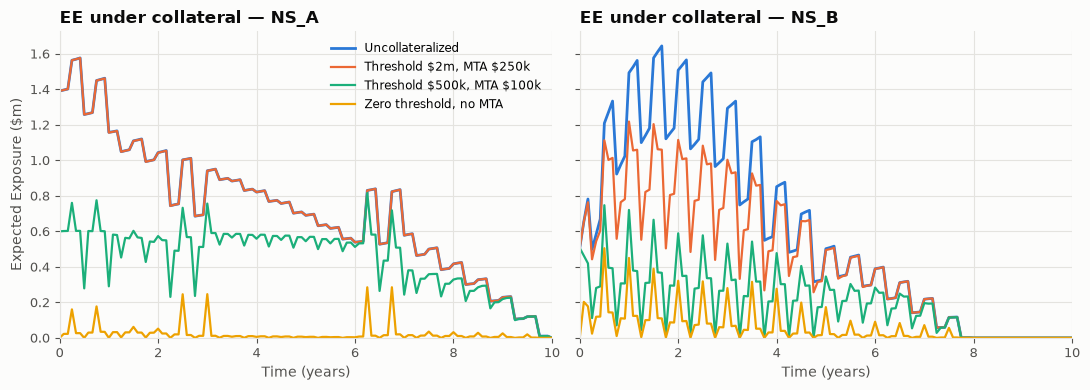

In [4]:
fig = plot_collateral_profiles(result['profiles'])

**Reading the profiles**

- **Threshold \$2m:** barely changes NS_A, whose netted exposure rarely exceeds \$2.25m ($H$ + MTA). It does cut NS_B's peaks, which reach well above that level.
- **Threshold \$500k:** collateral is called from day one. NS_A's exposure drops to about $H$ + MTA = \$0.6m, plus whatever the value moves during the two-week MPoR.
- **Zero threshold:** almost all exposure is gone. What remains comes from value moves inside the MPoR and from **cash-flow spikes**. On a date when we make a net coupon payment inside the window, the counterparty still holds collateral sized before that payment. The spikes sit on NS_B's semiannual fixed dates (it is a net fixed payer), and on NS_A only in the years when its trade mix makes it a net payer.

## 4. Gross → netted → collateralized CVA

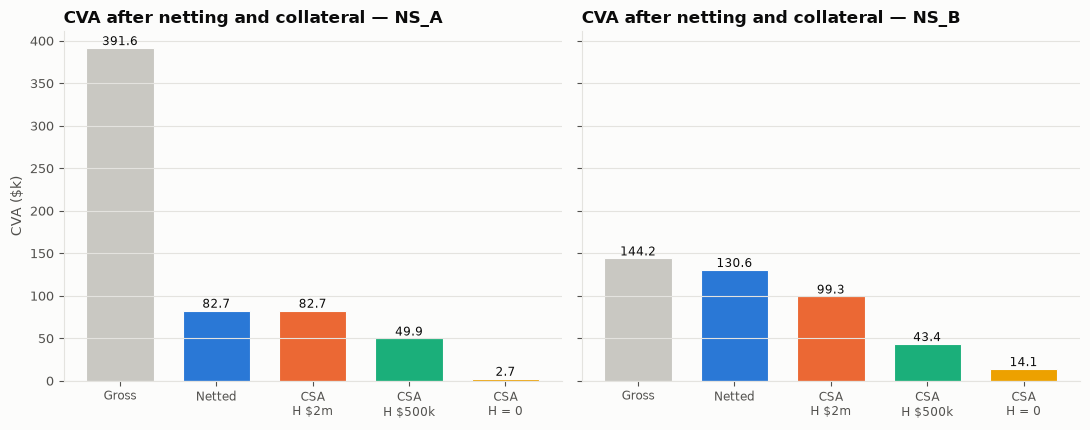

In [5]:
fig = plot_cva_mitigation(result['mitigation'])

In [6]:
result['mitigation'].style.format({'cva': '{:,.0f}', 'cva_se': '{:,.0f}', 'reduction_vs_gross': '{:.1%}'})

,netting_set_id,stage,cva,cva_se,reduction_vs_gross
0,NS_A,"Gross (no netting, no collateral)","391,613","1,586",0.0%
1,NS_A,"Netted, uncollateralized","82,715",208,78.9%
2,NS_A,"Netted + CSA: Threshold $2m, MTA $250k","82,698",207,78.9%
3,NS_A,"Netted + CSA: Threshold $500k, MTA $100k","49,909",71,87.3%
4,NS_A,"Netted + CSA: Zero threshold, no MTA","2,664",3,99.3%
5,NS_B,"Gross (no netting, no collateral)","144,217","1,328",0.0%
6,NS_B,"Netted, uncollateralized","130,591","1,348",9.4%
7,NS_B,"Netted + CSA: Threshold $2m, MTA $250k","99,306",842,31.1%
8,NS_B,"Netted + CSA: Threshold $500k, MTA $100k","43,449",300,69.9%
9,NS_B,"Netted + CSA: Zero threshold, no MTA","14,057",87,90.3%


- **NS_A:** netting does most of the work, because its trades offset each other. A zero-threshold CSA then removes nearly everything that is left.
- **NS_B:** netting does little because the book is one-directional, so collateral is what reduces CVA.

Even a zero-threshold CSA leaves a residual CVA. The MPoR gap and cash-flow spikes mean collateral never removes counterparty risk completely.

## 5. Margin period of risk

Under a zero threshold, the residual exposure is driven by how long the value can move uncollateralized. Pure diffusion would scale it like $\sqrt{\text{MPoR}}$.

In [7]:
result['mpor'].style.format({'epe_time_avg_ee': '{:,.0f}', 'cva': '{:,.0f}', 'cva_se': '{:,.0f}',
                             'cva_share_of_uncollateralized': '{:.1%}'})

,netting_set_id,mpor_days,epe_time_avg_ee,cva,cva_se,cva_share_of_uncollateralized
0,NS_A,7,"20,124","2,298",3,2.8%
1,NS_A,14,"23,251","2,664",3,3.2%
2,NS_A,28,"28,063","3,226",4,3.9%
3,NS_B,7,"61,489","11,571",71,8.9%
4,NS_B,14,"74,033","14,057",87,10.8%
5,NS_B,28,"94,530","18,149",115,13.9%


In [8]:
mpor = result['mpor'].pivot(index='mpor_days', columns='netting_set_id', values='cva')
pd.DataFrame({'CVA ratio 14d/7d': mpor.loc[14] / mpor.loc[7], 'CVA ratio 28d/14d': mpor.loc[28] / mpor.loc[14],
              'sqrt(2) for pure diffusion': np.sqrt(2)})

,CVA ratio 14d/7d,CVA ratio 28d/14d,sqrt(2) for pure diffusion
netting_set_id,,,
NS_A,1.16,1.21,1.41
NS_B,1.21,1.29,1.41


Doubling the MPoR raises residual CVA by less than $\sqrt2$. Part of the residual comes from coupons paid inside the window, which do not scale with the margin period, and from paths where the netting set was out of the money at the look-back date.

## 6. Checks (also enforced in `tests/test_collateral.py`)

In [9]:
s = result['summary']
rows = []
for ns, block in s.groupby('netting_set_id', sort=False):
    rows.append({'netting_set': ns,
                 'CVA falls as collateral tightens': bool(np.all(np.diff(block['cva'].to_numpy()) <= 1e-9)),
                 'uncollateralized = Phase D': bool(np.isclose(block['cva'].iloc[0], phase_d[ns], rtol=1e-12)),
                 'longer MPoR -> more CVA': bool(np.all(np.diff(result['mpor'].query('netting_set_id == @ns')['cva']) > 0))})
pd.DataFrame(rows)

,netting_set,CVA falls as collateral tightens,uncollateralized = Phase D,longer MPoR -> more CVA
0,NS_A,True,True,True
1,NS_B,True,True,True
